# TTC Ridership Analysis

This project explores Toronto Transit Commission ridership trends,
seasonal patterns, and recovery compared with 2019.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Resolve the data file relative to this notebook, tolerating a kernel started
# from the repo root (one level up) instead of from this folder.
DATA_FILE = Path("Data_source") / "TorontoMeasureData.csv"
data_path = next(
    (p / DATA_FILE for p in (Path.cwd(), Path.cwd() / "TTC") if (p / DATA_FILE).exists()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        f"{DATA_FILE} not found from {Path.cwd()} - see README 'Verify the data'"
    )

df = pd.read_csv(data_path)
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns")

df.head()

Loaded 508 rows x 4 columns


,Measure Name,Year,Period,Value
0,TTC Average Weekday Ridership,2007,Jan,1400000
1,TTC Average Weekday Ridership,2007,Feb,1486000
2,TTC Average Weekday Ridership,2007,Mar,1485000
3,TTC Average Weekday Ridership,2007,Apr,1491000
4,TTC Average Weekday Ridership,2007,May,1474000


In [2]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

df.info()

Rows: 508
Columns: 4
<class 'pandas.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Measure Name  508 non-null    str  
 1   Year          508 non-null    int64
 2   Period        462 non-null    str  
 3   Value         508 non-null    int64
dtypes: int64(2), str(2)
memory usage: 16.0 KB


## 🧹 Section 1 — Normalise & shape

Two of the four measures are monthly and two are annual, and they are published on different scales: monthly figures are **raw rides**, annual figures are in **thousands**. This section puts every observation on one schema so the rest of the notebook can join, aggregate and plot without special cases.


### 1.1 Build a tidy analysis frame

The raw export is close to tidy already, but three things would quietly corrupt any
downstream chart if left alone:

1. the two annual measures are published in **thousands**, the monthly ones in **raw rides**;
2. `Period` is null for the annual measures - those 46 nulls are structural, not missing data;
3. `Period` is a plain string, so it sorts alphabetically (Apr, Aug, Dec, ...).

This cell fixes all three and keeps the measurement basis explicit in a `unit` column,
so nothing later can accidentally sum an average into a total.


In [3]:
# --- Section 1.1 - normalise the export into one typed analysis frame ---

MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MONTH_NUM = {name: i for i, name in enumerate(MONTH_ORDER, start=1)}

WEEKDAY = "TTC Average Weekday Ridership"
MONTHLY = "TTC Monthly Ridership"
PEAK    = "TTC Annual Passenger Rides Peak (000s)"
NONPEAK = "TTC Annual Passenger Rides Non-Peak (000s)"

MONTHLY_MEASURES = [WEEKDAY, MONTHLY]
ANNUAL_MEASURES  = [PEAK, NONPEAK]

# 1) snake_case names; a null Period is exactly what marks an annual observation
clean = (
    df.rename(columns={"Measure Name": "measure", "Year": "year",
                       "Period": "period", "Value": "raw_value"})
      .assign(granularity=lambda d: np.where(d["period"].isna(), "annual", "monthly"))
)

# 2) month number + a real datetime index - monthly observations only
clean["month"] = clean["period"].map(MONTH_NUM).astype("Int8")

clean["date"] = pd.NaT
is_monthly = clean["month"].notna()
clean.loc[is_monthly, "date"] = pd.to_datetime(
    {"year":  clean.loc[is_monthly, "year"],
     "month": clean.loc[is_monthly, "month"].astype("int64"),
     "day":   1}
).to_numpy()

# 3) make the measurement basis explicit: can this number be summed?
clean["unit"] = clean["measure"].map(
    {WEEKDAY: "avg_weekday", MONTHLY: "total", PEAK: "total", NONPEAK: "total"}
)

# 4) annual measures are published in THOUSANDS -> rescale so every value is whole rides
clean["value"] = np.where(
    clean["granularity"] == "annual", clean["raw_value"] * 1000, clean["raw_value"]
).astype("int64")

# 5) flag the incomplete final year, derived from the data rather than hardcoded
PARTIAL_YEAR = int(clean.loc[is_monthly, "year"].max())
clean["is_partial_year"] = clean["year"] == PARTIAL_YEAR

# 6) ordered categoricals so month order is never alphabetical
clean = clean.assign(
    measure=pd.Categorical(clean["measure"],
                           categories=[WEEKDAY, MONTHLY, PEAK, NONPEAK], ordered=True),
    granularity=pd.Categorical(clean["granularity"],
                               categories=["monthly", "annual"], ordered=True),
    unit=pd.Categorical(clean["unit"], categories=["total", "avg_weekday"], ordered=True),
    period=pd.Categorical(clean["period"], categories=MONTH_ORDER, ordered=True),
    year=clean["year"].astype("int16"),
)[["measure", "granularity", "unit", "year",
   "period", "month", "date", "value", "is_partial_year"]]

print(f"clean: {clean.shape[0]:,} rows x {clean.shape[1]} columns")
print(f"       measures     {list(clean['measure'].cat.categories)}")
print(f"       partial year {PARTIAL_YEAR}")
print(f"       dtypes       {', '.join(f'{c}={t}' for c, t in clean.dtypes.astype(str).items())}")
clean.head()

clean: 508 rows x 9 columns
       measures     ['TTC Average Weekday Ridership', 'TTC Monthly Ridership', 'TTC Annual Passenger Rides Peak (000s)', 'TTC Annual Passenger Rides Non-Peak (000s)']
       partial year 2026
       dtypes       measure=category, granularity=category, unit=category, year=int16, period=category, month=Int8, date=datetime64[ns], value=int64, is_partial_year=bool


,measure,granularity,unit,year,period,month,date,value,is_partial_year
0,TTC Average Weekday Ridership,monthly,avg_weekday,2007,Jan,1,2007-01-01,1400000,False
1,TTC Average Weekday Ridership,monthly,avg_weekday,2007,Feb,2,2007-02-01,1486000,False
2,TTC Average Weekday Ridership,monthly,avg_weekday,2007,Mar,3,2007-03-01,1485000,False
3,TTC Average Weekday Ridership,monthly,avg_weekday,2007,Apr,4,2007-04-01,1491000,False
4,TTC Average Weekday Ridership,monthly,avg_weekday,2007,May,5,2007-05-01,1474000,False


### 1.2 Assert the profile (the README, executable)

Every data-quality claim in the README is checked here, so a refreshed upstream file
fails loudly instead of silently changing the story. The reconciliation assert is the
important one: it proves the `x1000` unit conversion is right, because the annual
peak + non-peak totals then reproduce the summed monthly ridership to within rounding.


In [4]:
# --- Section 1.2 - every README data-quality claim, checked in code ---

assert clean.shape == (508, 9), clean.shape
assert clean["value"].notna().all() and (clean["value"] > 0).all(), "null or zero rides"
assert not clean.duplicated(["measure", "year", "month"]).any(), "duplicate keys"

# 237 / 225 monthly, 23 / 23 annual (counts follow the categorical order above)
assert clean["measure"].value_counts(sort=False).tolist() == [237, 225, 23, 23], \
    clean["measure"].value_counts(sort=False).to_dict()
assert clean["granularity"].value_counts().sort_index().to_dict() == \
    {"annual": 46, "monthly": 462}

# the 46 nulls are structural: only the annual measures lack a month
assert clean["period"].isna().sum() == 46
assert clean.loc[clean["period"].isna(), "granularity"].eq("annual").all()
assert clean["month"].isna().sum() == 46 and clean["date"].isna().sum() == 46

# every month 1-12 present, no stray label
assert sorted(clean["month"].dropna().unique().tolist()) == list(range(1, 13))

# the final year is partial and holds Jan-Sep only (9 months x 2 monthly measures)
assert PARTIAL_YEAR == 2026
assert list(clean.loc[clean["is_partial_year"], "period"].unique()) == MONTH_ORDER[:9]
assert clean["is_partial_year"].sum() == 18

# per-measure coverage matches the documented windows
coverage = clean.groupby("measure", observed=True)["year"].agg(["min", "max"])
assert coverage.loc[WEEKDAY].tolist() == [2007, 2026]
assert coverage.loc[MONTHLY].tolist() == [2008, 2026]
assert coverage.loc[PEAK].tolist()    == [2003, 2025]
assert coverage.loc[NONPEAK].tolist() == [2003, 2025]

# --- the x1000 conversion is correct: annual peak+non-peak == summed monthly ---
monthly_sum = clean.query("measure == @MONTHLY").groupby("year")["value"].sum()
annual_sum  = clean.query("measure in @ANNUAL_MEASURES").groupby("year")["value"].sum()
recon = (annual_sum / monthly_sum).dropna()          # only the 2008-2025 overlap
assert (recon - 1).abs().max() <= 2e-4, (recon - 1).abs().max()

# --- headline numbers Sections 2-7 depend on ---
total = clean.query("measure == @MONTHLY").groupby("year")["value"].sum()
assert total[2019] == 525_470_000
assert abs(total[2020] / total[2019] - 1 - (-0.5720)) < 1e-3
assert total.idxmin() == 2021 and total[2021] == 197_841_000
assert abs(total[2025] / total[2019] - 1 - (-0.2141)) < 1e-3

peak  = clean.query("measure == @PEAK").set_index("year")["value"]
nonpk = clean.query("measure == @NONPEAK").set_index("year")["value"]
share = peak / (peak + nonpk)
assert abs(share[2003] - 0.4725) < 1e-4
assert abs(share[2025] - 0.4200) < 1e-4

print(f"validated {len(clean):,} rows | unit reconciliation error "
      f"{(recon - 1).abs().max():.6%} | peak share {share[2003]:.2%} (2003) "
      f"-> {share[2025]:.2%} (2025)")
coverage

validated 508 rows | unit reconciliation error 0.010893% | peak share 47.25% (2003) -> 42.00% (2025)


,min,max
measure,,
TTC Average Weekday Ridership,2007,2026
TTC Monthly Ridership,2008,2026
TTC Annual Passenger Rides Peak (000s),2003,2025
TTC Annual Passenger Rides Non-Peak (000s),2003,2025


### 1.3 Recover the 4-4-5 reporting periods

TTC publishes its monthly figures on **4-4-5 financial periods**, not calendar months:
eight 4-week blocks plus four 5-week blocks, so `8 x 28 + 4 x 35 = 364` days = 52 weeks
per year. That is why a naive month-over-month change shows a fake `+25%` every few
months, and why dividing by calendar days would overstate the long periods.

The periodisation is not published in this extract, so it is recovered here from two
independent columns (`monthly rides / average weekday rides` = weekday-equivalent days)
and asserted: the two regimes separate cleanly, and every complete year sums to 364 days.


In [5]:
# --- Section 1.3 - recover the 4-4-5 periodisation behind the monthly series ---

# Eight 4-week periods + four 5-week periods per year = 8*28 + 4*35 = 364 days (52 weeks).
# Mar and Jun are 5-week in every year on record; the other two 5-week slots rotate
# through Jan / Sep / Nov / Dec. Recovered from the data - the evidence is printed below.
FIVE_WEEK_MONTHS = {
    2008: ("Jan", "Mar", "Jun", "Sep"), 2009: ("Mar", "Jun", "Sep", "Dec"),
    2010: ("Mar", "Jun", "Sep", "Dec"), 2011: ("Mar", "Jun", "Sep", "Dec"),
    2012: ("Mar", "Jun", "Sep", "Dec"), 2013: ("Jan", "Mar", "Jun", "Sep"),
    2014: ("Jan", "Mar", "Jun", "Sep"), 2015: ("Mar", "Jun", "Sep", "Dec"),
    2016: ("Mar", "Jun", "Sep", "Dec"), 2017: ("Mar", "Jun", "Sep", "Dec"),
    2018: ("Jan", "Mar", "Jun", "Nov"), 2019: ("Jan", "Mar", "Jun", "Sep"),
    2020: ("Mar", "Jun", "Sep", "Dec"), 2021: ("Mar", "Jun", "Sep", "Dec"),
    2022: ("Mar", "Jun", "Sep", "Dec"), 2023: ("Mar", "Jun", "Sep", "Dec"),
    2024: ("Mar", "Jun", "Sep", "Dec"), 2025: ("Mar", "Jun", "Sep", "Dec"),
    2026: ("Mar", "Jun", "Sep"),          # partial year: Jan-Sep only
}

periods = (
    clean.query("measure == @MONTHLY")[["year", "period", "month", "value"]]
         .rename(columns={"value": "monthly_rides"})
         .merge(clean.query("measure == @WEEKDAY")[["year", "period", "value"]]
                     .rename(columns={"value": "avg_weekday"}),
                on=["year", "period"], how="left", validate="one_to_one")
)

# weekday-equivalent days: ~24.3 for a 4-week period, ~30.1 for a 5-week one
periods["implied_days"] = (periods["monthly_rides"] / periods["avg_weekday"]).round(2)

periods["period_weeks"] = [
    5 if per in FIVE_WEEK_MONTHS[int(yr)] else 4
    for yr, per in zip(periods["year"], periods["period"])
]
periods["period_days"] = periods["period_weeks"] * 7
periods["date"] = pd.to_datetime(
    dict(year=periods["year"], month=periods["month"].astype("int64"), day=1)
).astype("datetime64[ns]")

# --- 1.3 checks: the recovered periodisation must be self-consistent ---
assert len(periods) == 225, len(periods)
assert periods["implied_days"].notna().all()
assert not periods.duplicated(["year", "period"]).any()

# the invariant: Mar and Jun are 5-week in every year, without exception
assert periods.query("period in ('Mar', 'Jun')")["period_weeks"].eq(5).all()

# exactly four 5-week periods per complete year => 364 reporting days
days_per_year = periods.groupby("year")["period_days"].sum()
five_per_year = periods.groupby("year")["period_weeks"].apply(lambda s: int(s.eq(5).sum()))
assert days_per_year.loc[2008:2025].eq(364).all(), days_per_year
assert five_per_year.loc[2008:2025].eq(4).all(), five_per_year
assert days_per_year[2026] == 273, days_per_year[2026]   # Jan-Sep: 6 * 28 + 3 * 35
assert five_per_year[2026] == 3

# the two regimes separate cleanly, so the table is not fitted to noise.
# 2020-2022 excluded: the demand collapse breaks the weekday/weekend mix.
calm = periods[~periods["year"].isin([2020, 2021, 2022])]
median_5 = calm.loc[calm["period_weeks"].eq(5), "implied_days"].median()
median_4 = calm.loc[calm["period_weeks"].eq(4), "implied_days"].median()
assert median_5 > 29 and median_4 < 26 and (median_5 - median_4) > 4, (median_4, median_5)

print("reporting periods recovered from two independent columns:")
for weeks, label in ((4, "4-week"), (5, "5-week")):
    sub = calm.loc[calm["period_weeks"].eq(weeks), "implied_days"]
    print(f"  {label}: median {sub.median():5.2f} weekday-equivalent days "
          f"| {len(sub):3d} observations | range {sub.min():.1f}-{sub.max():.1f}")
print(f"  separation between regimes: {median_5 - median_4:.2f} days")
print(f"  reporting days per year: 364 for 2008-2025, {days_per_year[2026]} for 2026 (partial)")
print(f"  five-week periods per year: 4 for 2008-2025, {five_per_year[2026]} in 2026 (Jan-Sep only)")
periods.head()

reporting periods recovered from two independent columns:
  4-week: median 24.34 weekday-equivalent days | 126 observations | range 20.4-27.4
  5-week: median 30.26 weekday-equivalent days |  63 observations | range 27.6-38.4
  separation between regimes: 5.92 days
  reporting days per year: 364 for 2008-2025, 273 for 2026 (partial)
  five-week periods per year: 4 for 2008-2025, 3 in 2026 (Jan-Sep only)


,year,period,month,monthly_rides,avg_weekday,implied_days,period_weeks,period_days,date
0,2008,Jan,1,39242000,1379000,28.46,5,35,2008-01-01
1,2008,Feb,2,35150000,1476000,23.81,4,28,2008-02-01
2,2008,Mar,3,44924000,1519000,29.57,5,35,2008-03-01
3,2008,Apr,4,33965000,1446000,23.49,4,28,2008-04-01
4,2008,May,5,35357000,1479000,23.91,4,28,2008-05-01


### 1.4 Analysis frames

Everything from Section 2 onward works off three objects instead of re-querying `clean`:

- `monthly` - one row per reporting month (index = month start), carrying the daily rate
  and a 12-month rolling total
- `annual` - one row per year, with the derived peak-hour share
- `ytd(year)` - year-to-date ridership, so 2026 is never compared against a full year

The rolling 12-month total is the one place a partial year can be used honestly: a
trailing window ending in September 2026 spans twelve complete monthly observations,
so it needs no masking.


In [6]:
# --- Section 1.4 - the analysis frames every later section consumes ---

# monthly: one row per reporting period, indexed by month start
monthly = (
    clean.query("measure == @MONTHLY")
         .set_index("date")[["value", "is_partial_year"]]
         .rename(columns={"value": "ridership"})
)
monthly["avg_weekday"] = clean.query("measure == @WEEKDAY").set_index("date")["value"]
monthly = monthly.join(periods.set_index("date")[["period_weeks", "period_days"]])
monthly["rides_per_day"] = (monthly["ridership"] / monthly["period_days"]).round().astype("Int64")

# the 4-4-5 artefact is a sawtooth on the raw series; a trailing 12-month sum removes it
# without dropping any data - and stays valid through the partial final year
monthly["trailing_12m"] = monthly["ridership"].rolling(12, min_periods=12).sum().astype("Int64")

monthly.index.name = "month"
monthly = monthly[["ridership", "avg_weekday", "period_weeks", "period_days",
                   "rides_per_day", "trailing_12m", "is_partial_year"]]

# annual: peak and non-peak are separate published measures; total and share are derived
annual = pd.concat([
    clean.query("measure == @PEAK").set_index("year")["value"].rename("peak"),
    clean.query("measure == @NONPEAK").set_index("year")["value"].rename("non_peak"),
], axis=1)
annual["total"] = annual["peak"] + annual["non_peak"]
annual["peak_share"] = annual["peak"] / annual["total"]
annual.index.name = "year"


def ytd(year, through=None):
    """Ridership from January to `through` (month name), or to the last month on record."""
    frame = monthly.loc[str(year)]
    if through is not None:
        frame = frame[frame.index.month <= MONTH_NUM[through]]
    return int(frame["ridership"].sum())


# --- 1.4 checks ---
assert len(monthly) == 225
assert monthly["ridership"].notna().all() and monthly["rides_per_day"].notna().all()

# the index must be gap-free: rolling windows and pct_change() depend on it
stamp = pd.Series(monthly.index.year * 12 + monthly.index.month, index=monthly.index)
assert stamp.diff().dropna().eq(1).all(), "monthly index has a gap"
assert (stamp.iloc[0], monthly.index[-1].strftime("%Y-%m")) == (2008 * 12 + 1, "2026-09")

# annual frame: complete years only, and the derived columns are consistent
assert len(annual) == 23 and annual.index.min() == 2003 and annual.index.max() == 2025
assert annual["total"].notna().all()
assert (annual["peak"].lt(annual["total"])).all()
assert annual["peak_share"].between(0.39, 0.48).all()

# annual totals still reconcile to the monthly sums (both units are whole rides now)
monthly_year = monthly.groupby(monthly.index.year)["ridership"].sum()
overlap = annual.loc[2008:2025, "total"] / monthly_year
assert (overlap - 1).abs().max() <= 2e-4, (overlap - 1).abs().max()

# trailing window sanity: 12 observations, no partial-year distortion
assert monthly["trailing_12m"].notna().sum() == len(monthly) - 11
assert monthly["trailing_12m"].iloc[-1] == monthly["ridership"].iloc[-12:].sum()
assert int(monthly["trailing_12m"].iloc[-1]) == 409_975_000

# year-to-date helper: the only honest way to compare 2026
assert ytd(2026) == 303_355_000
assert ytd(2025, through="Sep") == 306_494_000
assert abs(ytd(2026) / ytd(2025, through="Sep") - 1 + 0.0102) < 5e-4

print(f"monthly : {monthly.shape[0]} rows x {monthly.shape[1]} cols "
      f"({monthly.index[0]:%Y-%m} to {monthly.index[-1]:%Y-%m})")
print(f"annual  : {annual.shape[0]} rows x {annual.shape[1]} cols "
      f"({annual.index.min()}-{annual.index.max()})")
print(f"trailing 12 months to {monthly.index[-1]:%b %Y}: "
      f"{monthly['trailing_12m'].iloc[-1]:,.0f} rides")
print(f"2026 YTD (Jan-Sep) {ytd(2026):,} vs 2025 YTD {ytd(2025, through='Sep'):,} "
      f"= {(ytd(2026) / ytd(2025, through='Sep') - 1) * 100:+.2f}%")
print(f"peak-hour share: {annual['peak_share'].iloc[0]:.2%} ({annual.index[0]}) "
      f"-> {annual['peak_share'].iloc[-1]:.2%} ({annual.index[-1]})")
monthly.head()

monthly : 225 rows x 7 cols (2008-01 to 2026-09)
annual  : 23 rows x 4 cols (2003-2025)
trailing 12 months to Sep 2026: 409,975,000 rides
2026 YTD (Jan-Sep) 303,355,000 vs 2025 YTD 306,494,000 = -1.02%
peak-hour share: 47.25% (2003) -> 42.00% (2025)


,ridership,avg_weekday,period_weeks,period_days,rides_per_day,trailing_12m,is_partial_year
month,,,,,,,
2008-01-01,39242000,1379000,5,35,1121200,<NA>,False
2008-02-01,35150000,1476000,4,28,1255357,<NA>,False
2008-03-01,44924000,1519000,5,35,1283543,<NA>,False
2008-04-01,33965000,1446000,4,28,1213036,<NA>,False
2008-05-01,35357000,1479000,4,28,1262750,<NA>,False


## 📈 Section 2 — Growth to 2016, then a plateau, then a collapse

Ridership grew 33% between 2003 and its high point, but the shape is not the simple
"growth until the pandemic" story it is usually told as: the peak was **2016**, and the
three years before COVID were already flat to falling. Then half the system disappeared in
a single year.

This section establishes that arc on the annual series, then decomposes it: absolute level,
peak vs non-peak composition, and the rate of change year over year.

Two framing choices matter for everything that follows:

- **calendar-year totals** stop at 2025, because the annual measures have no 2026 row;
- **a trailing 12-month sum** is used to carry the series into September 2026. Twelve
  reporting periods are 364 days regardless of where the 4-4-5 boundaries fall, so the
  window is directly comparable across eras and is not distorted by the partial year.


### 2.1 Chart style and figure export

One palette, one `save_fig()` helper, used by every figure in the notebook. Colours are
named by role rather than by hue so later sections stay visually consistent: `RED` for
ridership, `BLUE` for non-peak and comparative series, `AMBER` for the recovery era, `GREY`
for annotation furniture.

Each figure is written to `visualizations/` at 150 dpi with the data attribution baked in,
so the PNG files in the repo are the same ones the notebook displays.


In [7]:
# --- Section 2.1 - one chart style for the whole notebook ---
import matplotlib.pyplot as plt

FIG_DIR = data_path.parent.parent / "visualizations"   # .../TTC/visualizations
FIG_DIR.mkdir(exist_ok=True)

INK   = "#12232E"
RED   = "#DA291C"   # TTC red - total ridership
BLUE  = "#1F6F8B"   # non-peak rides / comparative series
AMBER = "#E9A13B"   # recovery era
GREY  = "#78868C"
LIGHT = "#DDE4E7"

CREDIT = ("Source: City of Toronto Open Data \u2014 Toronto's Dashboard Key Indicators "
          "(Open Government Licence \u2013 Toronto)")

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": LIGHT,
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": LIGHT,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "font.size": 10,
})


def save_fig(fig, name):
    """Write a figure into visualizations/ with the data credit, and report its size."""
    fig.text(0.5, -0.055, CREDIT, ha="center", va="top", fontsize=7, color=GREY)
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print(f"saved visualizations/{path.name}  ({path.stat().st_size / 1024:.0f} KB)")
    return path


assert FIG_DIR.is_dir(), FIG_DIR
print(f"figures -> {FIG_DIR.relative_to(FIG_DIR.parent)}/  |  "
      f"matplotlib {plt.matplotlib.__version__}")

figures -> visualizations/  |  matplotlib 3.11.2


### 2.2 Annual ridership, and the trailing 12-month series

The red line is the calendar-year total. It stops at 2025 because the annual measures have no
2026 row — so the blue dashed line carries the story forward: a trailing 12-month sum, which
is 364 reporting days at every point and therefore comparable across eras.

Two things the chart shows that the usual "growth until COVID" framing misses:

- the peak was **2016** (538.1M), not 2019. Ridership fell in three of the four years to 2018
  and had only clawed back to 525.5M — still 2.3% below 2016 — when the pandemic hit.
- the **strongest 12-month stretch on record is not a calendar year** either: the window
  ending February 2018 totalled 541.3M rides, because it combines a strong 2017 second half
  with a strong 2018 first half (271.6M) before the 2018 second half dropped away.


saved visualizations/02_annual_ridership.png  (130 KB)


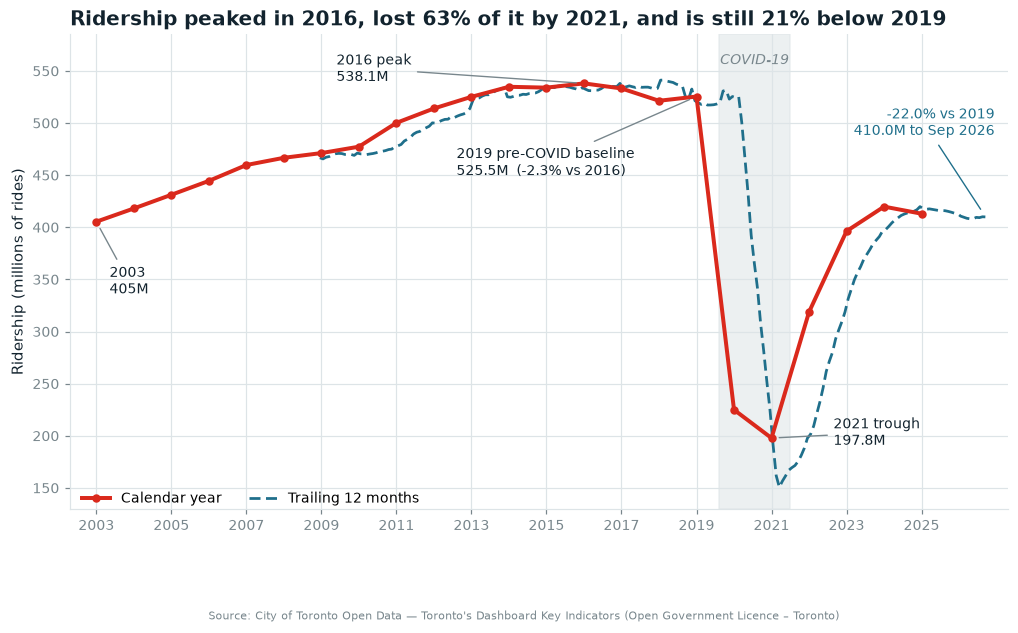

peak 2016 538.1M | 2019 525.5M (-2.3% vs peak) | trough 2021 197.8M (-63.2% vs peak) | strongest 12m 541.3M to Feb 2018


In [8]:
# --- Section 2.2 - annual ridership with a trailing 12-month overlay ---
fig, ax = plt.subplots(figsize=(11, 5.6))

years = annual.index.to_numpy()
total_m = annual["total"] / 1e6
t12_m = monthly["trailing_12m"].dropna() / 1e6
# the annual series is plotted on numeric years, so the monthly trailing window must be too -
# handing matplotlib a DatetimeIndex here would silently switch the axis to date units
t12_x = t12_m.index.year.to_numpy() + (t12_m.index.month.to_numpy() - 0.5) / 12

ax.plot(years, total_m, color=RED, lw=2.6, marker="o", ms=4.5, zorder=3,
        label="Calendar year")
ax.plot(t12_x, t12_m, color=BLUE, lw=1.8, ls=(0, (4, 2)), zorder=2,
        label="Trailing 12 months")

ax.axvspan(2019.6, 2021.5, color=LIGHT, alpha=0.55, zorder=0)
ax.text(2020.55, 560, "COVID-19", color=GREY, fontsize=9, ha="center",
        va="center", style="italic", zorder=4)


def tag(year, text, xytext):
    ax.annotate(text, xy=(year, total_m.loc[year]), xytext=xytext, fontsize=9,
                color=INK, ha="left", va="center", zorder=5,
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.9,
                                shrinkA=2, shrinkB=5))


peak_year = int(total_m.idxmax())
tag(2003, f"2003\n{total_m.loc[2003]:.0f}M", (2003.35, 348))
tag(peak_year, f"{peak_year} peak\n{total_m.loc[peak_year]:.1f}M",
    (peak_year - 6.6, 552))
tag(2019, f"2019 pre-COVID baseline\n{total_m.loc[2019]:.1f}M  "
          f"({(total_m.loc[2019] / total_m.loc[peak_year] - 1) * 100:+.1f}% vs {peak_year})",
    (2012.6, 462))
tag(2021, f"2021 trough\n{total_m.loc[2021]:.1f}M", (2022.65, 203))

ax.annotate(f"{(t12_m.iloc[-1] / total_m.loc[2019] - 1) * 100:+.1f}% vs 2019\n"
            f"{t12_m.iloc[-1]:.1f}M to Sep 2026",
            xy=(t12_x[-1], t12_m.iloc[-1]), xytext=(2026.95, 500),
            fontsize=9, color=BLUE, ha="right", va="center", zorder=5,
            arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.9, shrinkA=2, shrinkB=6))

ax.set_xlim(2002.3, 2027.3)
ax.set_ylim(130, 585)
ax.set_xticks(range(2003, 2027, 2))
ax.set_yticks(range(150, 586, 50))
ax.set_ylabel("Ridership (millions of rides)")
ax.set_title(f"Ridership peaked in {peak_year}, lost 63% of it by 2021, "
             f"and is still 21% below 2019")
ax.legend(loc="lower left", ncol=2, bbox_to_anchor=(0.0, -0.02))

png = save_fig(fig, "02_annual_ridership")
plt.show()

# --- checks ---
assert peak_year == 2016, peak_year
assert total_m.idxmin() == 2021
assert abs(total_m.loc[2016] - 538.1) < 0.1 and abs(total_m.loc[2019] - 525.5) < 0.1
assert abs(total_m.loc[2021] - 197.8) < 0.1
assert 540 < t12_m.max() < 542, t12_m.max()
assert png.exists() and png.stat().st_size > 30_000, png
print(f"peak {peak_year} {total_m.max():.1f}M | 2019 {total_m.loc[2019]:.1f}M "
      f"({(total_m.loc[2019] / total_m.max() - 1) * 100:+.1f}% vs peak) | trough "
      f"{total_m.idxmin()} {total_m.min():.1f}M ({(total_m.min() / total_m.max() - 1) * 100:+.1f}% vs peak) "
      f"| strongest 12m {t12_m.max():.1f}M to {t12_m.idxmax():%b %Y}")

### 2.3 Peak vs non-peak: the composition behind the total

The total alone hides a structural shift. Peak-hour and non-peak ridership are published as
separate measures, so the two can be stacked to see *which* half of the system lost more —
and which half came back. Both bands are labelled directly on the chart, so no legend is
needed. Peak-hour demand is the commuter market, and it is the part that stayed at home.


saved visualizations/02_peak_vs_nonpeak.png  (90 KB)


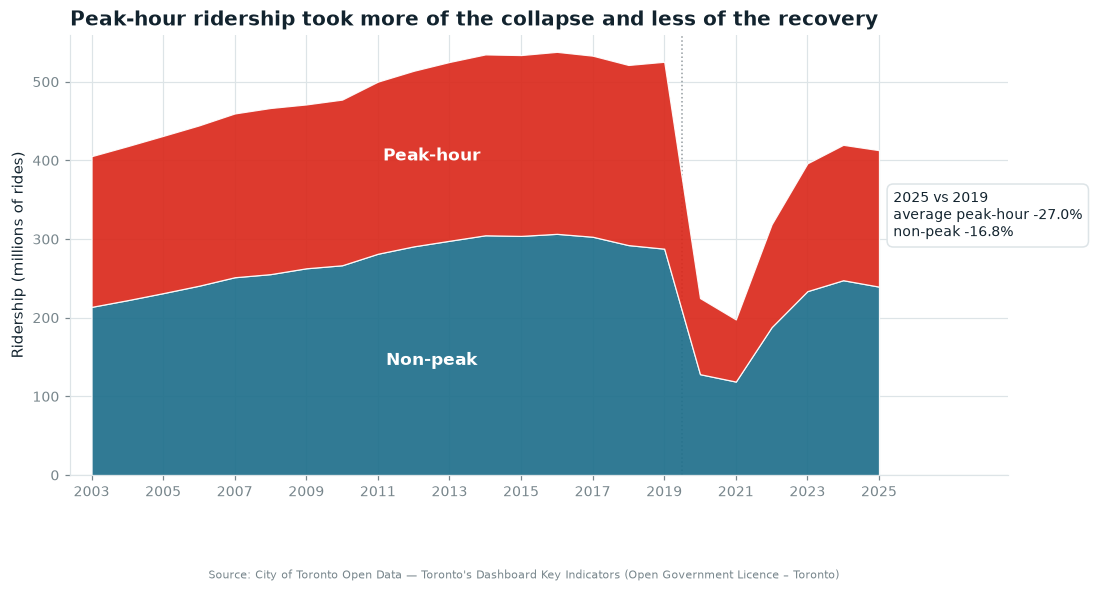

2025 vs 2019: peak-hour -26.99% | non-peak -16.77% | gap 10.2 pts


In [9]:
# --- Section 2.3 - peak vs non-peak composition ---
fig, ax = plt.subplots(figsize=(11, 5.2))

non_m = (annual["non_peak"] / 1e6).to_numpy()
peak_m = (annual["peak"] / 1e6).to_numpy()

ax.stackplot(years, non_m, peak_m, labels=["Non-peak", "Peak-hour"],
             colors=[BLUE, RED], alpha=0.92, edgecolor="white", linewidth=0.8, zorder=2)
ax.axvline(2019.5, color=INK, lw=1, ls=":", alpha=0.45, zorder=1)

# direct labels beat a legend for two stacked bands
ax.text(2012.5, 140, "Non-peak", color="white", fontsize=11, weight="bold",
        ha="center", zorder=3)
ax.text(2012.5, 400, "Peak-hour", color="white", fontsize=11, weight="bold",
        ha="center", zorder=3)

peak_rec = (annual.loc[2025, "peak"] / annual.loc[2019, "peak"] - 1) * 100
non_rec = (annual.loc[2025, "non_peak"] / annual.loc[2019, "non_peak"] - 1) * 100

ax.annotate(f"2025 vs 2019\naverage peak-hour {peak_rec:+.1f}%\nnon-peak {non_rec:+.1f}%",
            xy=(2025.4, 330), fontsize=9, color=INK, ha="left", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.45", fc="white", ec=LIGHT, lw=1))

ax.set_xlim(2002.4, 2028.6)
ax.set_ylim(0, 560)
ax.set_xticks(range(2003, 2026, 2))
ax.set_yticks(range(0, 551, 100))
ax.set_ylabel("Ridership (millions of rides)")
ax.set_title("Peak-hour ridership took more of the collapse and less of the recovery")

png = save_fig(fig, "02_peak_vs_nonpeak")
plt.show()

# --- checks ---
assert (annual["non_peak"] > annual["peak"]).all()
assert np.allclose(annual["peak"] + annual["non_peak"], annual["total"])
assert peak_rec < non_rec, (peak_rec, non_rec)
assert abs(peak_rec + 27.0) < 0.2 and abs(non_rec + 16.7) < 0.2, (peak_rec, non_rec)
assert png.exists() and png.stat().st_size > 30_000, png
print(f"2025 vs 2019: peak-hour {peak_rec:+.2f}% | non-peak {non_rec:+.2f}% "
      f"| gap {non_rec - peak_rec:.1f} pts")

### 2.4 Year-over-year change

Rates, not levels, so the growth era, the plateau and the shock sit on one scale. Splitting
the bars into four eras makes the corrected story legible: eleven years of uninterrupted
growth to 2014, a **four-year plateau** in which ridership fell three times and ended 2.3%
below the 2016 peak, then the 57% collapse of 2020, then a recovery that has already stalled
again in 2025.


saved visualizations/02_yoy_growth.png  (79 KB)


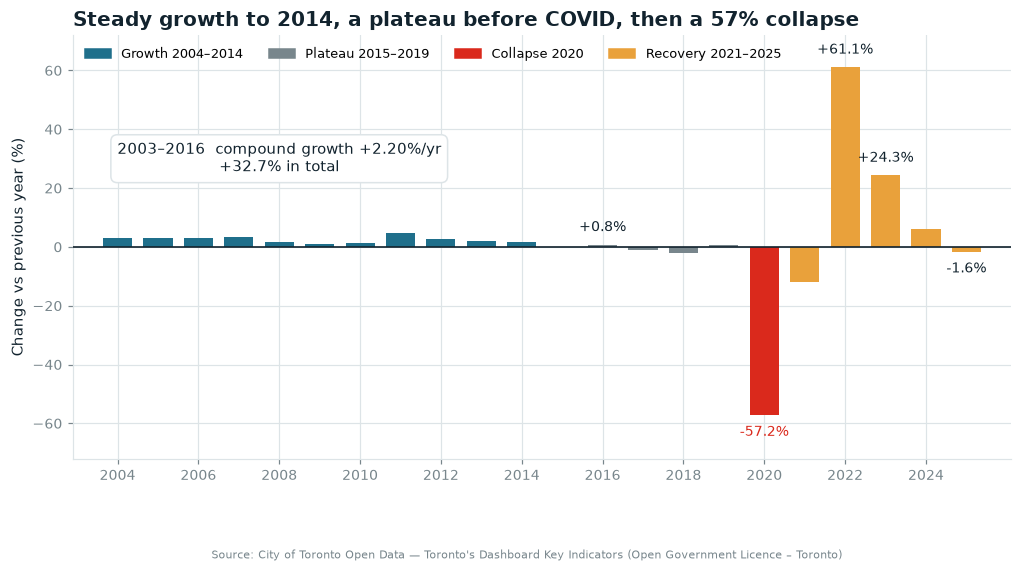

growth 2004-2014: all 11 years up | plateau 2015-2019: 3 down, -2.3% vs 2016 | 2003-2016 CAGR +2.20%/yr | 2025 -1.62%


In [10]:
# --- Section 2.4 - year-over-year change, split by era ---
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 5.0))

yoy = annual["total"].pct_change().mul(100).dropna()
peak_year = int(annual["total"].idxmax())

ERAS = {"growth": (2004, 2014, BLUE),
        "plateau": (2015, 2019, GREY),
        "collapse": (2020, 2020, RED),
        "recovery": (2021, 2025, AMBER)}
colors = [next(c for lo, hi, c in ERAS.values() if lo <= y <= hi) for y in yoy.index]

ax.bar(yoy.index, yoy.to_numpy(), color=colors, width=0.72, zorder=3)
ax.axhline(0, color=INK, lw=1.1, zorder=4)

for year, value in yoy.items():
    if abs(value) >= 20 or year in (peak_year, 2025):
        ax.text(year, value + (3.5 if value > 0 else -3.5), f"{value:+.1f}%",
                ha="center", va="bottom" if value > 0 else "top",
                fontsize=9, color=RED if year == 2020 else INK, zorder=5)

cagr = (annual.loc[peak_year, "total"] / annual.loc[2003, "total"]) ** (1 / (peak_year - 2003)) - 1
ax.annotate(f"2003\u2013{peak_year}  compound growth {cagr * 100:+.2f}%/yr\n"
            f"{(annual.loc[peak_year, 'total'] / annual.loc[2003, 'total'] - 1) * 100:+.1f}% in total",
            xy=(2008, 30), fontsize=9.5, color=INK, ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.45", fc="white", ec=LIGHT, lw=1))

ax.legend(handles=[Patch(color=c, label=(f"{name.capitalize()} {lo}" if lo == hi
                                          else f"{name.capitalize()} {lo}\u2013{hi}"))
                   for name, (lo, hi, c) in ERAS.items()],
          loc="upper left", ncol=4, fontsize=8.5)
ax.set_xlim(2002.9, 2026.1)
ax.set_ylim(-72, 72)
ax.set_xticks(range(2004, 2026, 2))
ax.set_yticks(range(-60, 61, 20))
ax.set_ylabel("Change vs previous year (%)")
ax.set_title("Steady growth to 2014, a plateau before COVID, then a 57% collapse")

png = save_fig(fig, "02_yoy_growth")
plt.show()

# --- checks ---
assert abs(yoy[2020] + 57.18) < 0.02, yoy[2020]
assert abs(yoy[2022] - 61.11) < 0.02, yoy[2022]
assert 0.021 < cagr < 0.023, cagr
assert yoy.loc[2004:2014].gt(0).all(), "growth era should be all-positive"
assert yoy.loc[2015:2019].lt(0).sum() == 3, yoy.loc[2015:2019].to_dict()
assert (annual.loc[2019, "total"] < annual.loc[peak_year, "total"])
assert png.exists() and png.stat().st_size > 25_000, png
print(f"growth 2004-2014: all {len(yoy.loc[2004:2014])} years up | "
      f"plateau 2015-2019: {int(yoy.loc[2015:2019].lt(0).sum())} down, "
      f"{(annual.loc[2019, 'total'] / annual.loc[peak_year, 'total'] - 1) * 100:+.1f}% vs {peak_year} | "
      f"2003-{peak_year} CAGR {cagr * 100:+.2f}%/yr | 2025 {yoy[2025]:+.2f}%")